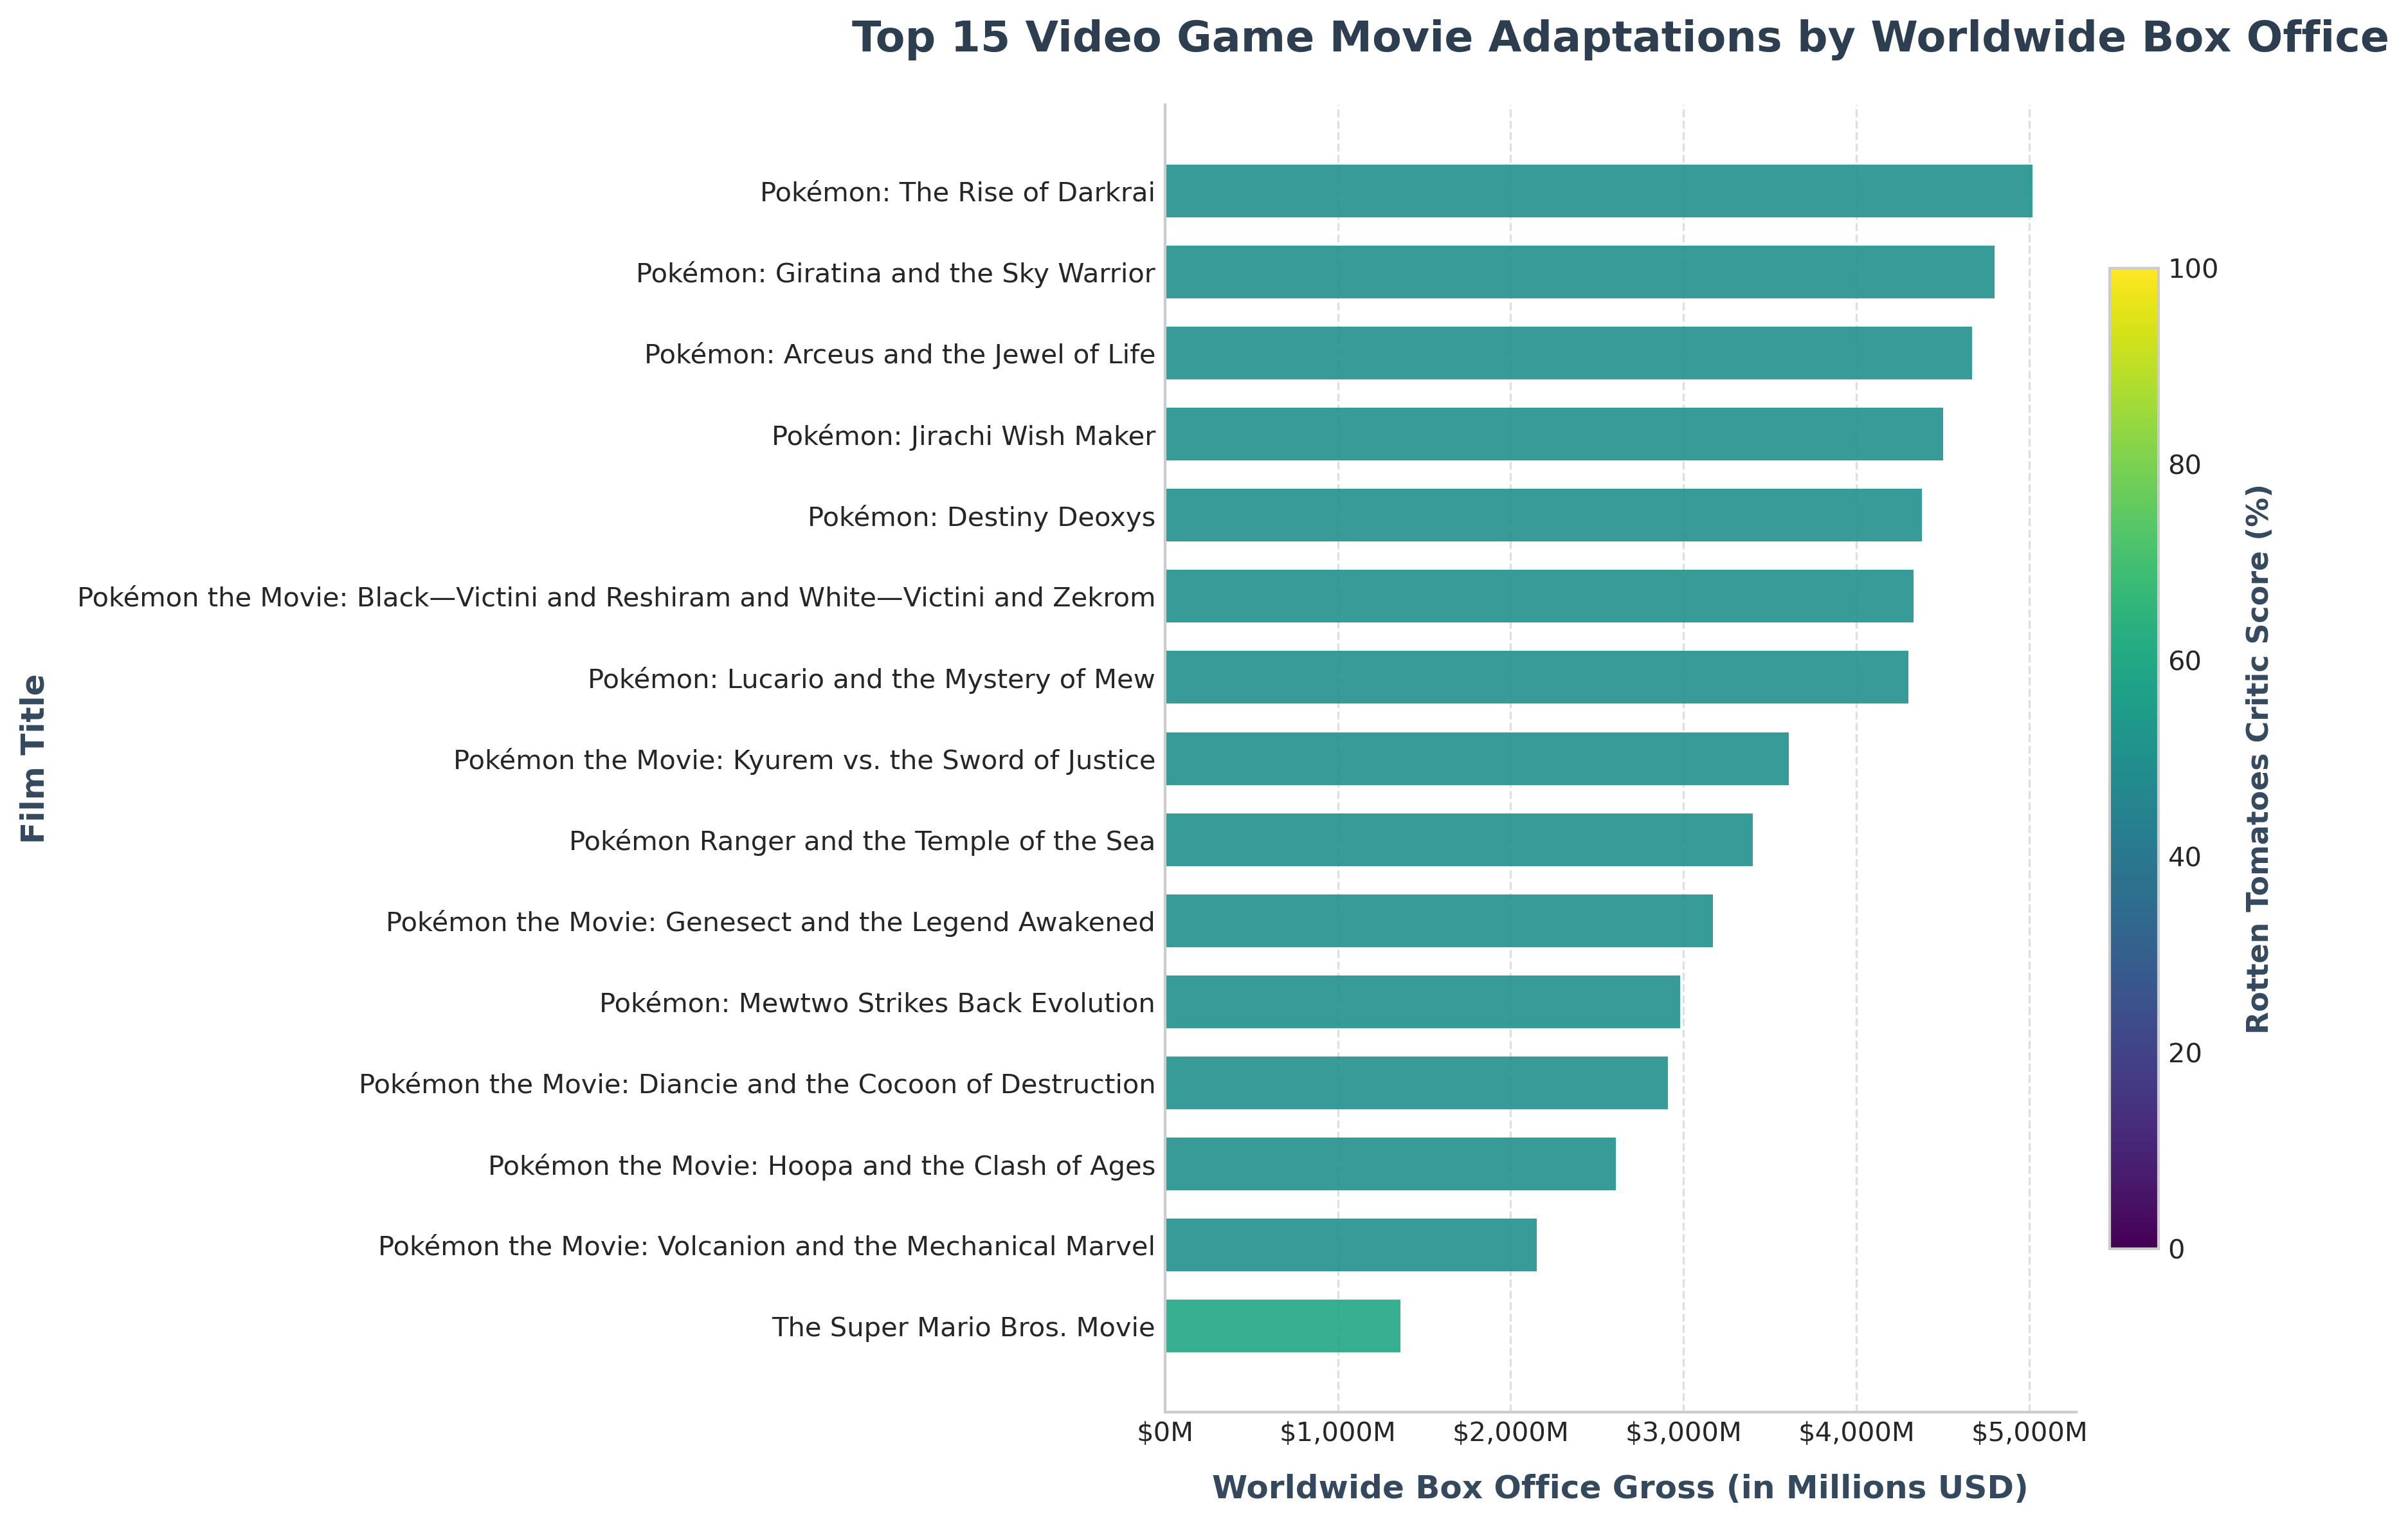

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# 1. Load the TidyTuesday dataset
url = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/main/data/2026/2026-06-09/game_films.csv"
df = pd.read_csv(url)

# 2. Data Cleaning & Preparation
# Drop rows without box office figures or titles, then get top 15 by worldwide box office
df_clean = df.dropna(subset=["worldwide_box_office", "title"]).copy()
top_films = df_clean.sort_values(
    by="worldwide_box_office", ascending=False
).head(15)

# Convert box office to millions for cleaner axis labels
top_films["box_office_millions"] = top_films["worldwide_box_office"] / 1e6

# 3. Set up the Figure Aesthetics
plt.style.use("seaborn-v0_8-whitegrid")
fig, ax = plt.subplots(figsize=(12, 8), dpi=300)

# Set up colormap mapping Rotten Tomatoes scores to bar colors
norm = plt.Normalize(vmin=0, vmax=100)
sm = plt.cm.ScalarMappable(cmap="viridis", norm=norm)
sm.set_array([])

# Reverse the order so the highest-grossing film is at the top
titles = top_films["title"][::-1]
box_office = top_films["box_office_millions"][::-1]
rt_scores = top_films["rotten_tomatoes"].fillna(50)[::-1]  # Fallback for missing scores

# Draw horizontal bars
bars = ax.barh(
    titles,
    box_office,
    color=plt.cm.viridis(norm(rt_scores)),
    edgecolor="none",
    height=0.65,
    alpha=0.9
)

# 4. Customizing Labels and Typography
ax.set_title(
    "Top 15 Video Game Movie Adaptations by Worldwide Box Office",
    fontsize=16,
    fontweight="bold",
    pad=20,
    color="#2c3e50"
)
ax.set_xlabel(
    "Worldwide Box Office Gross (in Millions USD)",
    fontsize=12,
    fontweight="bold",
    labelpad=10,
    color="#34495e"
)
ax.set_ylabel(
    "Film Title",
    fontsize=12,
    fontweight="bold",
    labelpad=10,
    color="#34495e"
)

# Format x-axis ticks with dollar currency
ax.xaxis.set_major_formatter("${x:,.0f}M")

# Add a professional colorbar legend for Rotten Tomatoes scores
cbar = fig.colorbar(sm, ax=ax, orientation="vertical", pad=0.03, shrink=0.75)
cbar.set_label(
    "Rotten Tomatoes Critic Score (%)",
    fontsize=11,
    fontweight="bold",
    labelpad=10,
    color="#34495e"
)

# Remove top and right spines for a modern, clean look
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)

# Add subtle grid lines behind bars
ax.xaxis.grid(True, linestyle="--", alpha=0.5, color="#bdc3c7")
ax.yaxis.grid(False)

# 5. Save and Display
plt.tight_layout()
plt.savefig("top_game_films_box_office.png", dpi=300, bbox_inches="tight")
plt.show()